In [29]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [17]:
df = pd.read_csv('ford.csv')

In [3]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17966 entries, 0 to 17965
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         17966 non-null  object 
 1   year          17966 non-null  int64  
 2   price         17966 non-null  int64  
 3   transmission  17966 non-null  object 
 4   mileage       17966 non-null  int64  
 5   fuelType      17966 non-null  object 
 6   tax           17966 non-null  int64  
 7   mpg           17966 non-null  float64
 8   engineSize    17966 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 1.2+ MB


In [5]:
df['transmission'].value_counts()

transmission
Manual       15518
Automatic     1361
Semi-Auto     1087
Name: count, dtype: int64

In [6]:
df['model'].value_counts()

model
 Fiesta                   6557
 Focus                    4588
 Kuga                     2225
 EcoSport                 1143
 C-MAX                     543
 Ka+                       531
 Mondeo                    526
 B-MAX                     355
 S-MAX                     296
 Grand C-MAX               247
 Galaxy                    228
 Edge                      208
 KA                        199
 Puma                       80
 Tourneo Custom             69
 Grand Tourneo Connect      59
 Mustang                    57
 Tourneo Connect            33
 Fusion                     16
 Streetka                    2
 Ranger                      1
 Escort                      1
 Transit Tourneo             1
Focus                        1
Name: count, dtype: int64

In [7]:
df['fuelType'].value_counts()

fuelType
Petrol      12179
Diesel       5762
Hybrid         22
Electric        2
Other           1
Name: count, dtype: int64

In [8]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='object')

In [9]:
df['year'].value_counts()

year
2017    4888
2018    4014
2019    3194
2016    2331
2015    1368
2014     805
2013     609
2020     258
2012     115
2011      94
2009      91
2010      67
2008      57
2007      32
2005      16
2006      13
2004       4
2003       3
2002       3
1998       1
1996       1
2000       1
2060       1
Name: count, dtype: int64

In [18]:
# standardization
std_df=df.copy()
cols_to_scale=['mileage','tax',
       'mpg', 'engineSize']

scaler=StandardScaler()
std_df[cols_to_scale]=scaler.fit_transform(df[cols_to_scale])


In [20]:
std_df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,-0.380998,Petrol,0.591358,-0.020442,-0.811386
1,Focus,2018,14000,Manual,-0.733359,Petrol,0.591358,-0.020442,-0.811386
2,Focus,2017,13000,Manual,-0.560132,Petrol,0.591358,-0.020442,-0.811386
3,Fiesta,2019,17500,Manual,-0.662640,Petrol,0.510727,-1.738890,0.345070
4,Fiesta,2019,16500,Automatic,-1.123724,Petrol,0.510727,-0.909294,-0.811386


In [21]:
encoded_std_df=pd.get_dummies(std_df,columns=['model','year','transmission','fuelType'],dtype=int)

In [22]:
encoded_std_df.head()

,price,mileage,tax,mpg,engineSize,model_ B-MAX,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,...,year_2020,year_2060,transmission_Automatic,transmission_Manual,transmission_Semi-Auto,fuelType_Diesel,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,12000,-0.380998,0.591358,-0.020442,-0.811386,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
1,14000,-0.733359,0.591358,-0.020442,-0.811386,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
2,13000,-0.560132,0.591358,-0.020442,-0.811386,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
3,17500,-0.662640,0.510727,-1.738890,0.345070,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,1
4,16500,-1.123724,0.510727,-0.909294,-0.811386,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1


In [25]:
y=encoded_std_df['price']
X=encoded_std_df.drop(columns=['price'])

In [30]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [31]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()

In [32]:
model.fit(X_train,y_train)

LinearRegression()

In [33]:
y_pred=model.predict(X_test)

In [36]:
y_pred

array([ 6925.41909356,  8516.7186769 ,  9239.15868794, ...,
       28119.72448675,  8926.24258871, 17241.80042033])

In [37]:
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error,accuracy_score
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print(f"R2 Score (Accuracy): {r2:.4f} ({r2 * 100:.2f}%)")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

R2 Score (Accuracy): 0.8807 (88.07%)
Mean Absolute Error (MAE): 1217.38
Root Mean Squared Error (RMSE): 1635.31


In [38]:
print("Train R2:", model.score(X_train, y_train))
print("Test R2:", model.score(X_test, y_test))


Train R2: 0.8802305113906872
Test R2: 0.8806790447917842


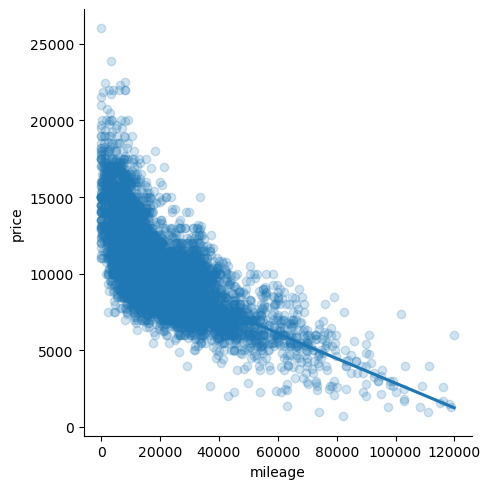

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot mileage vs. price with a curved trendline (lowess=True)
sns.lmplot(data=df[df['model'].str.strip() == 'Fiesta'], x='mileage', y='price', lowess=True, scatter_kws={'alpha':0.2})
plt.show()
